In [3]:
import pandas as pd

donnees = pd.read_csv("etudiants_classification_500.csv")
donnees

,etudiant,heures_etude,note_partiel,resultat
0,E001,1.0,3.0,Échec
1,E002,2.0,5.0,Échec
2,E003,3.0,2.0,Échec
3,E004,4.0,6.0,Réussite
4,E005,6.0,7.0,Réussite
...,...,...,...,...
495,E496,1.0,1.5,Échec
496,E497,7.2,9.4,Réussite
497,E498,7.8,3.3,Échec
498,E499,4.2,5.4,Échec


In [4]:
X = donnees.drop(["etudiant", "resultat"], axis=1)

In [5]:
X

,heures_etude,note_partiel
0,1.0,3.0
1,2.0,5.0
2,3.0,2.0
3,4.0,6.0
4,6.0,7.0
...,...,...
495,1.0,1.5
496,7.2,9.4
497,7.8,3.3
498,4.2,5.4


In [6]:
Y = donnees["resultat"]
Y

0         Échec
1         Échec
2         Échec
3      Réussite
4      Réussite
         ...   
495       Échec
496    Réussite
497       Échec
498       Échec
499    Réussite
Name: resultat, Length: 500, dtype: object

In [7]:
from sklearn.model_selection import train_test_split

In [8]:
train_test_split(X,Y)

[     heures_etude  note_partiel
 488           5.1           3.0
 250           3.8           5.9
 258           7.9           5.6
 72            4.4           4.2
 34            4.7           8.4
 ..            ...           ...
 495           1.0           1.5
 406           7.4           2.9
 169           3.4           5.1
 438           3.1          10.0
 210           5.5           4.6
 
 [375 rows x 2 columns],
      heures_etude  note_partiel
 7             5.1           7.3
 12            1.8           8.1
 84            4.8           5.2
 494           6.9           7.8
 180           8.0           6.2
 ..            ...           ...
 191           0.8           5.4
 47            6.1           1.8
 63            1.7           8.5
 9             7.1           7.9
 42            0.9           4.3
 
 [125 rows x 2 columns],
 488       Échec
 250    Réussite
 258    Réussite
 72     Réussite
 34     Réussite
          ...   
 495       Échec
 406    Réussite
 169       Échec
 

In [9]:
# verification des valeurs uniques
Y.unique()

array(['Échec', 'Réussite'], dtype=object)

In [10]:
# encodage des resultat à 0 et 1 pour les rendre numerique
Y = Y.map({'Échec':0, 'Réussite':1})
Y

0      0
1      0
2      0
3      1
4      1
      ..
495    0
496    1
497    0
498    0
499    1
Name: resultat, Length: 500, dtype: int64

In [11]:
# separation des données de d'entrainement de données de test
train_test_split(X,Y)

[     heures_etude  note_partiel
 363           2.6           7.9
 302           1.3           0.2
 448           6.1           5.3
 166           6.9           4.1
 116           6.4           3.7
 ..            ...           ...
 290           7.0           9.2
 218           1.6           4.6
 48            0.0           3.6
 296           1.2           3.0
 278           4.6           6.7
 
 [375 rows x 2 columns],
      heures_etude  note_partiel
 458           6.4           4.7
 141           3.8           8.6
 248           7.6           4.9
 499           5.8           8.4
 358           7.7           3.9
 ..            ...           ...
 29            1.8           6.9
 213           5.6           5.4
 466           3.0           5.1
 25            5.2           4.4
 490           0.4           2.1
 
 [125 rows x 2 columns],
 363    1
 302    0
 448    1
 166    1
 116    0
       ..
 290    1
 218    0
 48     0
 296    0
 278    1
 Name: resultat, Length: 375, dtype: int64,


In [12]:
# affectation de données
x_train, x_test, y_train, y_test = train_test_split(X,Y, random_state=42, test_size=.2, stratify=Y)

In [13]:
# importation des classes necessaires

from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier

from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

In [14]:
# creation des model
modeles = {
    'SVM': make_pipeline(StandardScaler(), SVC(kernel= 'rbf', C=1)),
     'DT':DecisionTreeClassifier(max_depth=4, random_state= 42),
     'KNN':make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=5))
 }

In [15]:
resultat = []

# importation des metrics
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, ConfusionMatrixDisplay)
import matplotlib.pyplot as plt


In [16]:
meilleur_score = -1
meilleur_modele = None
meilleur_nom = None


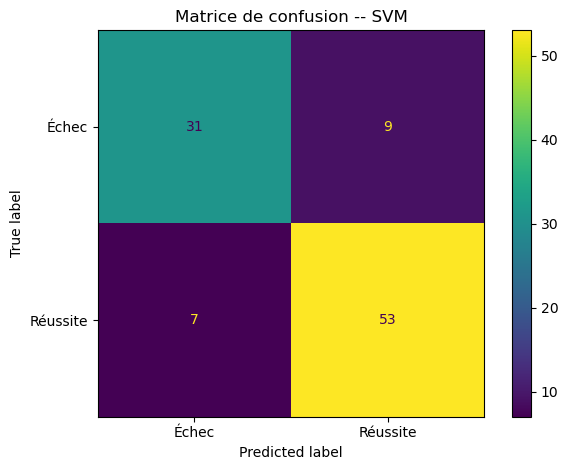

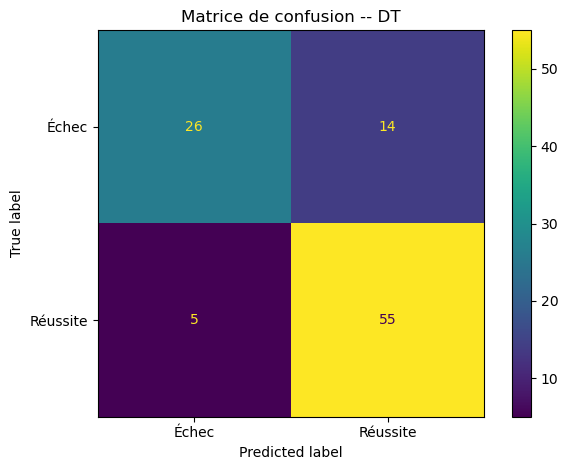

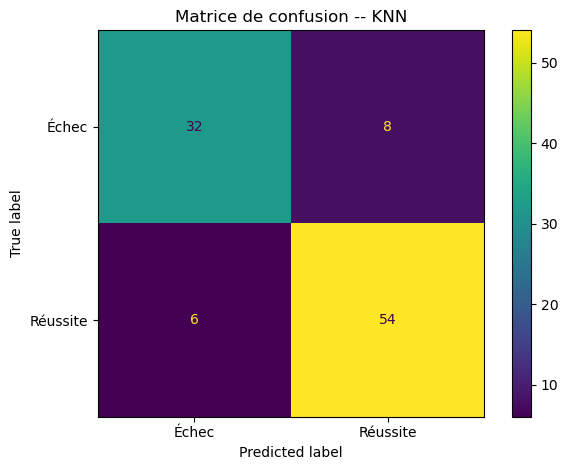

In [17]:
# iteration 
for nom, modele in modeles.items():
    modele.fit(x_train, y_train)
    y_pred = modele.predict(x_test)
    accuracy = accuracy_score(y_test, y_pred)
    precision = precision_score(y_test, y_pred, zero_division=0)
    recall = recall_score(y_test, y_pred, zero_division=0)
    f1 = f1_score(y_test, y_pred)
    resultat.append([nom, accuracy, precision, recall, f1])
    matrice = confusion_matrix(y_test, y_pred)
# affichage de la matrice de confusion
    affichage = ConfusionMatrixDisplay(confusion_matrix = matrice,
                                        display_labels = ['Échec', 'Réussite'])
    
    affichage.plot(values_format='d')
    plt.title( f"Matrice de confusion -- {nom}")
    plt.tight_layout()

    # determination du meilleur modele
    if f1 > meilleur_score:
        meilleur_modele = modele
        meilleur_nom = nom

In [18]:
resultats = pd.DataFrame(resultat)

In [19]:
resultats

,0,1,2,3,4
0,SVM,0.84,0.854839,0.883333,0.868852
1,DT,0.81,0.797101,0.916667,0.852713
2,KNN,0.86,0.870968,0.900000,0.885246


In [20]:
meilleur_modele

Pipeline(steps=[('standardscaler', StandardScaler()),
                ('kneighborsclassifier', KNeighborsClassifier())])

In [21]:
from sklearn.model_selection import cross_val_score

scores = cross_val_score(meilleur_modele, x_train, y_train, cv=5)

score_min = scores.mean()
score = pd.DataFrame(scores)

print("Score moyen : ", scores.mean())

Score moyen :  0.8399999999999999


In [22]:
import joblib

In [23]:
score

,0
0,0.8250
1,0.8250
2,0.8375
3,0.8625
4,0.8500


In [24]:
joblib.dump(meilleur_modele, "monModeleML.joblib")

['monModeleML.joblib']